#### ESCUELA POLIECTNICA NACIONAL 
#### MTODOS NUMRICOS 
#### DANNY CAIZA 

## DEBER - METODO DE BISECCION 
25 de Octubre de 2026
_________________________

In [2]:
def bisection(f, a, b, tol, N0=1000):
  """Implementación del Algoritmo 2.1 del método de la bisección."""
  i = 1
  fa = f(a)

  if fa * f(b) > 0:
    raise ValueError(
        "El intervalo no cumple con el cambio de signo: f(a)*f(b) > 0"
    )

  while i <= N0:
    p = a + (b - a) / 2
    fp = f(p)

    if fp == 0 or (b - a) / 2 < tol:
      return p, i

    i += 1
    if fa * fp > 0:
      a = p
      fa = fp
    else:
      b = p

  raise Exception(f"El método fracasó después de {N0} iteraciones")

2. Raíces con el Algoritmo 2.1

In [4]:
import numpy as np


def f2(x):
  return x**3 - 7 * x**2 + 14 * x - 6


intervals_sec2 = [(0, 1), (1, 3.2), (3.2, 4)]
print("- Ejercicio 1: x^3 - 7x^2 + 14x - 6 = 0 ---")
for iv in intervals_sec2:
  raiz, iters = bisection(f2, iv[0], iv[1], tol=10**-2)
  print(f"Intervalo {iv}: Raíz = {raiz:.6f} | Iteraciones = {iters}")


def f_sin(x):
  return x - 2 * np.sin(x)

raiz_sin, iters_sin = bisection(f_sin, 1.5, 2.5, tol=10**-5)
print(f"\n- Ejercicio 2: x = 2*sin(x) ---")
print(f"Raíz = {raiz_sin:.6f} | Iteraciones = {iters_sin}")

def f_tan(x):
  return x - np.tan(x)

raiz_tan, iters_tan = bisection(f_tan, 4.0, 4.8, tol=10**-5)
print(f"\n- Ejercicio 3: x = tan(x) ---")
print(f"Raíz = {raiz_tan:.6f} | Iteraciones = {iters_tan}")

def f_exp(x):
  return x**2 - 1 - np.exp(1 - x**2)


raiz_exp, iters_exp = bisection(f_exp, -2, 0, tol=10**-3)
print(f"\n- Ejercicio 4: x^2 - 1 = e^(1 - x^2) ---")
print(f"Raíz = {raiz_exp:.6f} | Iteraciones = {iters_exp}")

- Ejercicio 1: x^3 - 7x^2 + 14x - 6 = 0 ---
Intervalo (0, 1): Raíz = 0.585938 | Iteraciones = 7
Intervalo (1, 3.2): Raíz = 3.002344 | Iteraciones = 8
Intervalo (3.2, 4): Raíz = 3.418750 | Iteraciones = 7

- Ejercicio 2: x = 2*sin(x) ---
Raíz = 1.895500 | Iteraciones = 17


ValueError: El intervalo no cumple con el cambio de signo: f(a)*f(b) > 0

4. Problemas Aplicados

In [6]:
import numpy as np

L = 10.0
r = 1.0
V = 12.4


def f_trough(h):
  return (
      L
      * (
          0.5 * np.pi * r**2
          - r**2 * np.arcsin(h / r)
          - h * np.sqrt(r**2 - h**2)
      )
      - V
  )

h_sol, iters_h = bisection(f_trough, 0.0, 1.0, tol=0.01)
# La profundidad desde el fondo es r - h
profundidad = r - h_sol

print("- Ejercicio 1: Abrevadero ---")
print(f"h (desde arriba) = {h_sol:.4f} cm")
print(f"Profundidad del agua (r - h) = {profundidad:.2f} cm")


s0 = 300.0
m_obj = 0.25
k_obj = 0.1
g_obj = 9.81


def f_fall(t):
  return (
      s0
      - (k_obj * m_obj * g_obj / k_obj**2) * t
      + (m_obj**2 * g_obj / k_obj**2) * (1 - np.exp(-k_obj * t / m_obj))
  )

t_sol, iters_t = bisection(f_fall, 0.0, 30.0, tol=0.01)

print("\n- Ejercicio 2: Caída libre ---")
print(f"Tiempo en llegar al piso = {t_sol:.3f} s")

- Ejercicio 1: Abrevadero ---
h (desde arriba) = 0.1641 cm
Profundidad del agua (r - h) = 0.84 cm

- Ejercicio 2: Caída libre ---
Tiempo en llegar al piso = 14.729 s


5. Grafique y=x y y=tanx en [0,5] (limite el eje y, por ejemplo, a [−10,10]) y marque la solución de x=tanx que encontró. Suba la gráfica.

Gráfica guardada exitosamente como 'grafica_tan_x.png'


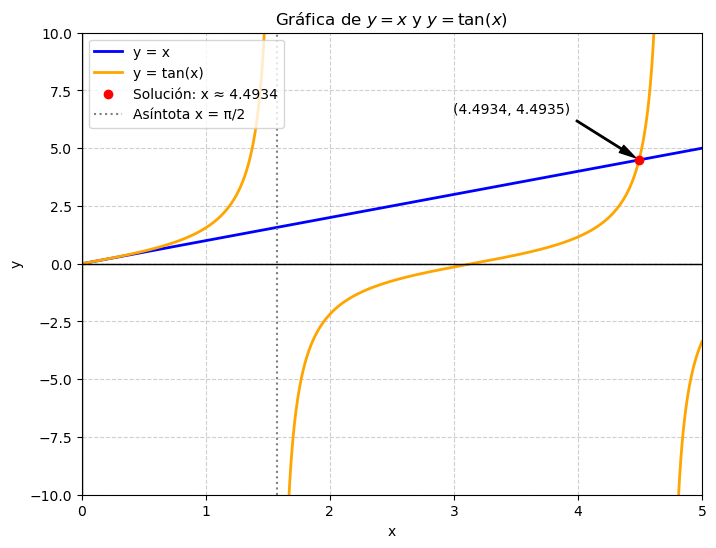

In [7]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 5, 1000)
y_x = x
y_tan = np.tan(x)
y_tan_masked = np.ma.masked_where(np.abs(y_tan) > 50, y_tan)

plt.figure(figsize=(8, 6))
plt.plot(x, y_x, label='y = x', color='blue', linewidth=2)
plt.plot(x, y_tan_masked, label='y = tan(x)', color='orange', linewidth=2)

x_sol = 4.493414
y_sol = np.tan(x_sol) 

plt.scatter([x_sol], [y_sol], color='red', zorder=5, label='Solución: x ≈ 4.4934')
plt.annotate(f'({x_sol:.4f}, {y_sol:.4f})', 
             xy=(x_sol, y_sol), 
             xytext=(x_sol - 1.5, y_sol + 2),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.xlim(0, 5)
plt.ylim(-10, 10)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(np.pi/2, color='gray', linestyle=':', label='Asíntota x = \u03c0/2')

plt.title('Gráfica de $y = x$ y $y = \\tan(x)$')
plt.xlabel('x')
plt.ylabel('y')
plt.axhline(0, color='black',linewidth=1)
plt.axvline(0, color='black',linewidth=1)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left')

plt.savefig('grafica_tan_x.png', dpi=300, bbox_inches='tight')
print("Gráfica guardada exitosamente como 'grafica_tan_x.png'")